<a href="https://colab.research.google.com/github/Cyber-GenAI/machine-learning/blob/main/Classification/APT_Intent_Classification_from_Sectors_v1_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intent-Based Classification of APT Target Sectors

**Objective:** Reorganize the distribution table of multi-stage attack patterns based on "Intent Class" using the `apt_target_sectors.json` dataset (GraphQL output from OpenCTI/STIX) and enrich the specificity file with the `apt_category` label.

This notebook:
1. Loads the `targets` relationship dataset linking Intrusion Sets/Threat Actors to Sectors.
2. Maps Sectors to specific Intent Classes (excluding "Other").
3. Counts each relationship (campaign/targeting event) as a single instance—if an APT group targets multiple sectors, each is counted and labeled individually.
4. Generates detailed class statistics and compares them with the table from the research paper.
5. Enriches the `apt_total_specificity_v19.2.xlsx` file with the `apt_category` label, producing `apt_total_specificity_apt_category_v19.2.xlsx`.
6. Prepares data for machine learning algorithms (creating feature vectors based on TTPs).

## 1. Import Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json
from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 2. Load Dataset (GraphQL response)

The `apt_target_sectors.json` file is the output of the following query:

```graphql
query APTTargetSectors {
  stixCoreRelationships(
    relationship_type: "targets"
    fromTypes: ["Intrusion-Set", "Threat-Actor"]
    toTypes: ["Sector"]
    first: 100
  ) {
    edges {
      node {
        id
        from {
          __typename
          ... on IntrusionSet { id name aliases }
          ... on ThreatActor  { id name aliases }
        }
        to {
          __typename
          ... on Sector { id name }
        }
      }
    }
    pageInfo { endCursor hasNextPage }
  }
}
```

> **Note:** In the current data, `hasNextPage` is `true`; pagination can be continued to ensure full coverage.

In [ ]:
# مسیرها — در Colab مسیر Drive را تنظیم کنید
DATA_PATH = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/.json/apt_target_sectors.json')
# DATA_PATH = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/.json/apt_target_sectors.json')  # Colab

with open(DATA_PATH, encoding='utf-8') as f:
    raw = json.load(f)

edges = raw['data']['stixCoreRelationships']['edges']
page_info = raw['data']['stixCoreRelationships']['pageInfo']

print(f"Total relationships (edges): {len(edges)}")
print(f"hasNextPage: {page_info['hasNextPage']}")
print(f"endCursor: {page_info['endCursor'][:40]}...")

Total relationships (edges): 839
hasNextPage: True
endCursor: WyJyZWxhdGlvbnNoaXAtLTkxNDJkNDljLTA3NWQt...


## 3. Flatten GraphQL edges → DataFrame

In [ ]:
rows = []
for edge in edges:
    node = edge['node']
    frm = node['from']
    to = node['to']
    rows.append({
        'relationship_id': node['id'],
        'group_id': frm.get('id'),
        'group_name': frm.get('name'),
        'group_type': frm.get('__typename'),
        'aliases': frm.get('aliases') or [],
        'sector_id': to.get('id'),
        'sector_name': to.get('name'),
    })

df = pd.DataFrame(rows)
print(f"Shape: {df.shape}")
print(f"Unique groups: {df['group_name'].nunique()}")
print(f"Unique sectors: {df['sector_name'].nunique()}")
df.head(10)

Shape: (839, 7)
Unique groups: 353
Unique sectors: 111


,relationship_id,group_id,group_name,group_type,aliases,sector_id,sector_name
0,6d6fdc41-96b4-4be6-b79f-bc53e051ffc2,d8b44a68-13ac-4489-b3f5-ab946535f614,Vietnamese group,IntrusionSet,[],117fedf1-7b32-46b3-b689-9a16ac16b1a5,Technology
1,f7bb2928-8d30-4897-8b06-1c8064490484,21b6d9bc-4d45-4ee3-b4b0-b8818a1ecd68,FIN6,IntrusionSet,"[Magecart Group 6, ITG08, Skeleton Spider, TAAL, Camouflage Tempest]",edc8695d-5087-43ae-bbd9-f50d0190a95b,Finance
2,d57f6da8-0211-4cac-b60d-77de1815dc64,554eae2d-8e6b-4541-8637-fec8b6b72379,Multiple Russian state-backed groups,IntrusionSet,[],fbe265c2-d2cf-49e7-a122-5d095702efba,Telecommunications
3,c4e8fe59-0c3f-444f-8f86-ce8ed8360a87,3560c044-68b4-4026-87fd-2860ee81fe03,Saaiwc Group,IntrusionSet,[],ecf29398-ee6a-4b72-b689-53872efd6962,Military
4,97331a69-83eb-4c7b-83d1-b1ace9b2956f,42249221-0ce1-43eb-8ec2-adea44495398,AIRASHI,IntrusionSet,[],74c5fafa-5e51-49d4-881c-3d220a2e016b,Gaming
5,9978806c-e553-4fb1-adef-a7e6de111540,f318cbb9-29f2-45f0-9d63-1dc241e16076,BlackSuit,IntrusionSet,[],dfd983c7-7c70-4476-96f4-23e5b4ab1719,Manufacturing
6,c62965c0-b712-4b58-b1dc-92651f9a782a,9ec822b8-be7f-47cd-adb1-1a262608d11c,BianLian,IntrusionSet,[],dfd983c7-7c70-4476-96f4-23e5b4ab1719,Manufacturing
7,51016770-ec84-4782-9d65-ff7c934d693f,3d1f9fdc-8d9f-484f-96ac-85c3cc957624,Andariel,IntrusionSet,"[PLUTONIUM, Onyx Sleet, Silent Chollima]",3fd4383d-ffc8-41b9-b70d-a9ad149de710,Defense
8,c86cf0ce-4d2a-4d17-a179-fb4bf454dfc2,ab3f9f15-2a9c-4aef-b758-01924f173253,Lazarus Group,IntrusionSet,"[HIDDEN COBRA, Guardians of Peace, NICKEL ACADEMY, ZINC, Labyrinth Chollima, Diamond Sleet]",7e87d43e-2bdc-48bd-919a-4e4ac457a48f,Construction
9,0a97e51b-219a-4898-95ce-5a0d21b0a64c,175410cb-55fd-4575-b8ef-abafa2f5f0ac,Cyber Anarchy Squad (C.A.S),IntrusionSet,[],117fedf1-7b32-46b3-b689-9a16ac16b1a5,Technology


## 4. Sector → Intent Class Mapping

Intent classes (excluding "Other" as a primary class) — 16 classes.

In [ ]:
SECTOR_TO_INTENT = {
    'Government': 'Government / Public Sector', 'Political': 'Government / Public Sector',
    'public sector': 'Government / Public Sector', 'Public Services': 'Government / Public Sector',
    'Human Rights': 'Government / Public Sector', 'Humanitarian': 'Government / Public Sector',
    'NGO': 'Government / Public Sector', 'Religious': 'Government / Public Sector',
    'Journalists': 'Government / Public Sector', 'Social Services': 'Government / Public Sector',
    'Defense': 'Defense & Military', 'Defence': 'Defense & Military', 'Military': 'Defense & Military',
    'Finance': 'Financial Services', 'Financial': 'Financial Services', 'Banking': 'Financial Services',
    'Bank': 'Financial Services', 'Banking & Finance': 'Financial Services',
    'Financial Services': 'Financial Services', 'Investment': 'Financial Services',
    'Fintech': 'Financial Services', 'Insurance': 'Financial Services',
    'Wealth Management': 'Financial Services', 'Bitcoin': 'Financial Services',
    'Crypto': 'Financial Services', 'Cryptocurrency': 'Financial Services',
    'Accounting': 'Financial Services', 'Gambling': 'Financial Services',
    'Technology': 'Technology & IT', 'Information Technology': 'Technology & IT',
    'IT': 'Technology & IT', 'Tech': 'Technology & IT', 'High Tech': 'Technology & IT',
    'Software': 'Technology & IT', 'Software Automation': 'Technology & IT',
    'Semiconductor': 'Technology & IT', 'Technical Services': 'Technology & IT',
    'Telecommunications': 'Telecommunications', 'Telecommunication': 'Telecommunications',
    'Telecoms': 'Telecommunications', 'Telecom': 'Telecommunications',
    'Communications': 'Telecommunications', 'ISPs': 'Telecommunications',
    'Healthcare': 'Healthcare & Public Health', 'Health': 'Healthcare & Public Health',
    'Medical': 'Healthcare & Public Health', 'Public Health': 'Healthcare & Public Health',
    'Biomedical': 'Healthcare & Public Health', 'Biotechnology': 'Healthcare & Public Health',
    'Pharmaceutical': 'Healthcare & Public Health', 'Pharmaceuticals': 'Healthcare & Public Health',
    'Education': 'Education & Academia', 'Higher Education': 'Education & Academia',
    'Academic': 'Education & Academia', 'Academic Institutions': 'Education & Academia',
    'Research': 'Education & Academia',
    'Energy': 'Energy & Utilities', 'Electricity': 'Energy & Utilities',
    'Oil And Gas': 'Energy & Utilities', 'Nuclear': 'Energy & Utilities',
    'Utilities': 'Energy & Utilities', 'Ics': 'Energy & Utilities',
    'Manufacturing': 'Manufacturing & Industrial', 'Industrial': 'Manufacturing & Industrial',
    'Heavy Industry': 'Manufacturing & Industrial', 'Industrial Machinery': 'Manufacturing & Industrial',
    'Chemical': 'Manufacturing & Industrial', 'Automotive': 'Manufacturing & Industrial',
    'Engineering': 'Manufacturing & Industrial', 'Construction': 'Manufacturing & Industrial',
    'Mining': 'Manufacturing & Industrial',
    'Diplomatic': 'Diplomacy & Foreign Affairs', 'Diplomacy': 'Diplomacy & Foreign Affairs',
    'Embassy': 'Diplomacy & Foreign Affairs', 'Foreign Affairs': 'Diplomacy & Foreign Affairs',
    'Foreign': 'Diplomacy & Foreign Affairs',
    'Aerospace': 'Aerospace & Aviation', 'Aviation': 'Aerospace & Aviation',
    'Airline': 'Aerospace & Aviation', 'Space': 'Aerospace & Aviation',
    'Critical Infrastructure': 'Critical Infrastructure & Transportation',
    'Commercial Facilities': 'Critical Infrastructure & Transportation',
    'Transportation': 'Critical Infrastructure & Transportation',
    'Logistics': 'Critical Infrastructure & Transportation',
    'Maritime': 'Critical Infrastructure & Transportation',
    'Shipping': 'Critical Infrastructure & Transportation',
    'Travel': 'Critical Infrastructure & Transportation',
    'Tourism': 'Critical Infrastructure & Transportation',
    'Emergency Services': 'Critical Infrastructure & Transportation',
    'Media': 'Media & Entertainment', 'Entertainment': 'Media & Entertainment',
    'Gaming': 'Media & Entertainment', 'Sports': 'Media & Entertainment',
    'Retail': 'Retail & Consumer Services', 'Consumer Services': 'Retail & Consumer Services',
    'Hospitality': 'Retail & Consumer Services', 'Hotel': 'Retail & Consumer Services',
    'Food and Beverage': 'Retail & Consumer Services',
    'Food and Agriculture': 'Agriculture & Food', 'Agriculture': 'Agriculture & Food',
    'Professional Services': 'Professional & Business Services',
    'Consulting': 'Professional & Business Services', 'Business Services': 'Professional & Business Services',
    'BPO': 'Professional & Business Services', 'Human Resources': 'Professional & Business Services',
    'Employment': 'Professional & Business Services', 'Legal': 'Professional & Business Services',
    'Law': 'Professional & Business Services', 'Architecture': 'Professional & Business Services',
    'Development': 'Professional & Business Services', 'Trade': 'Professional & Business Services',
}
print(f"Mapped sector keywords: {len(SECTOR_TO_INTENT)}")

Mapped sector keywords: 111


In [ ]:
def map_sector(sector: str) -> str:
    return SECTOR_TO_INTENT.get(sector, 'Unmapped / Residual')

df['intent_class'] = df['sector_name'].apply(map_sector)

unmapped = df[df['intent_class'] == 'Unmapped / Residual']
print(f"Total instances: {len(df)}")
print(f"Mapped: {len(df) - len(unmapped)} ({100*(len(df)-len(unmapped))/len(df):.1f}%)")
print(f"Unmapped: {len(unmapped)}")
if len(unmapped):
    print("Unmapped sectors:", unmapped['sector_name'].value_counts().to_dict())

Total instances: 839
Mapped: 839 (100.0%)
Unmapped: 0


## 5. Distribution Table — Intent Class (by Campaign / Relationship Instance)

Each `targets` relationship is considered an **Instance**.

In [ ]:
intent_dist = (
    df['intent_class']
    .value_counts()
    .rename_axis('Intent Class')
    .reset_index(name='# Number of Instances')
)
intent_dist['Percentage'] = (intent_dist['# Number of Instances'] / intent_dist['# Number of Instances'].sum() * 100).round(1)
intent_dist = intent_dist.sort_values('# Number of Instances', ascending=False).reset_index(drop=True)

print("=" * 70)
print("Distribution of Multi-Stage Attack Patterns by Intent Class")
print("=" * 70)
display(intent_dist)

Distribution of Multi-Stage Attack Patterns by Intent Class


,Intent Class,# Number of Instances,Percentage
0,Government / Public Sector,148,17.6
1,Financial Services,108,12.9
2,Technology & IT,82,9.8
3,Defense & Military,66,7.9
4,Manufacturing & Industrial,66,7.9
5,Healthcare & Public Health,53,6.3
6,Telecommunications,52,6.2
7,Energy & Utilities,51,6.1
8,Critical Infrastructure & Transportation,45,5.4
9,Education & Academia,41,4.9


## 6. Visualization

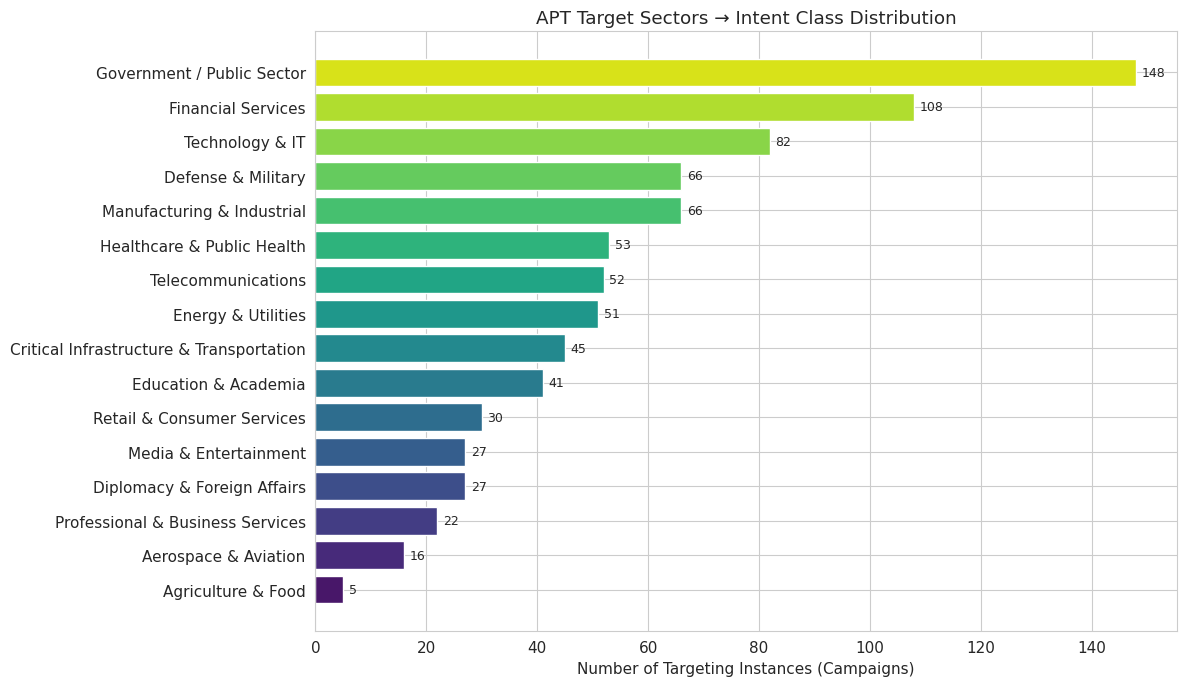

In [ ]:
plot_df = intent_dist[intent_dist['Intent Class'] != 'Unmapped / Residual'].copy()
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(plot_df['Intent Class'][::-1], plot_df['# Number of Instances'][::-1],
               color=sns.color_palette('viridis', len(plot_df)))
ax.set_xlabel('Number of Targeting Instances (Campaigns)')
ax.set_title('APT Target Sectors → Intent Class Distribution')
for bar, val in zip(bars, plot_df['# Number of Instances'][::-1]):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)
plt.tight_layout()
plt.show()

## 7. Groups with Multiple Intent Classes

In [ ]:
group_intent_counts = (
    df.groupby(['group_name', 'intent_class'])
    .size()
    .reset_index(name='instances')
)
multi_intent_groups = (
    group_intent_counts
    .groupby('group_name')['intent_class']
    .nunique()
    .reset_index(name='n_intents')
)
multi_intent_groups = multi_intent_groups[multi_intent_groups['n_intents'] > 1].sort_values('n_intents', ascending=False)
print(f"Groups targeting more than one Intent Class: {len(multi_intent_groups)}")
display(multi_intent_groups.head(15))

Groups targeting more than one Intent Class: 185


,group_name,n_intents
23,APT41,12
183,MUSTANG PANDA,10
168,Lazarus,10
231,RansomHub,9
313,UNC4841,8
53,BlackSuit,7
160,Kimsuky,7
209,OilRig,7
196,MuddyWater,7
120,FIN7,7


## 8. Enrich Specificity Excel with apt_category

**Input:** `apt_total_specificity_v19.2.xlsx`
**Output:** `apt_total_specificity_apt_category_v19.2.xlsx`

For each Intrusion-Set:
- `apt_category` = Dominant Intent class (highest number of campaigns)
- `all_intent_classes` = All classes (separated by `|`)
- `n_campaigns` = Number of target relationships
- `n_intent_classes` = Number of distinct classes

In [ ]:
primary_intent = (
    df.groupby('group_name')['intent_class']
    .agg(lambda x: x.value_counts().index[0])
    .to_dict()
)
all_intents = (
    df.groupby('group_name')['intent_class']
    .agg(lambda x: ' | '.join(sorted(set(x))))
    .to_dict()
)
campaign_counts = df.groupby('group_name').size().to_dict()
n_intent_classes = {g: len(v.split(' | ')) for g, v in all_intents.items()}
print(f"Groups with sector-based intent labels: {len(primary_intent)}")

Groups with sector-based intent labels: 353


In [ ]:
SPEC_PATH = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/.xlsx/apt_total_specificity_v19.2.xlsx')
spec = pd.read_excel(SPEC_PATH)
print(f"Specificity Excel shape: {spec.shape}")
print(f"Columns: {list(spec.columns)}")

Specificity Excel shape: (819, 5)
Columns: ['intrusion_set_id', 'intrusion_set_name', 'processed_sequence_unique_tokens', 'total_specificity', 'apt_category']


In [ ]:
spec['apt_category'] = None
spec['all_intent_classes'] = None
spec['n_campaigns'] = 0
spec['n_intent_classes'] = 0

spec['_name_key'] = spec['intrusion_set_name'].astype(str).str.strip().str.lower()
sector_name_map = {g.strip().lower(): g for g in primary_intent.keys()}

matched = 0
for idx in range(len(spec)):
    key = spec.at[idx, '_name_key']
    if key in sector_name_map:
        orig = sector_name_map[key]
        spec.at[idx, 'apt_category'] = primary_intent[orig]
        spec.at[idx, 'all_intent_classes'] = all_intents[orig]
        spec.at[idx, 'n_campaigns'] = int(campaign_counts[orig])
        spec.at[idx, 'n_intent_classes'] = int(n_intent_classes[orig])
        matched += 1

spec = spec.drop(columns=['_name_key'])
cols = [
    'intrusion_set_id', 'intrusion_set_name', 'processed_sequence_unique_tokens',
    'total_specificity', 'apt_category', 'all_intent_classes',
    'n_campaigns', 'n_intent_classes',
]
spec = spec[cols]

print(f"Matched groups: {matched} / {len(spec)}")
print()
print("apt_category distribution:")
print(spec['apt_category'].value_counts(dropna=False).to_string())

Matched groups: 342 / 819

apt_category distribution:
apt_category
None                                        477
Government / Public Sector                   60
Financial Services                           58
Technology & IT                              38
Defense & Military                           27
Manufacturing & Industrial                   23
Education & Academia                         21
Telecommunications                           18
Energy & Utilities                           18
Critical Infrastructure & Transportation     17
Healthcare & Public Health                   16
Retail & Consumer Services                   16
Diplomacy & Foreign Affairs                   9
Media & Entertainment                         9
Aerospace & Aviation                          7
Professional & Business Services              4
Agriculture & Food                            1


In [ ]:
OUT_XLSX = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/.xlsx/apt_total_specificity_apt_category_v19.2.xlsx')
spec.to_excel(OUT_XLSX, index=False)
print(f"Saved → {OUT_XLSX}")
print(f"Shape: {spec.shape}")
print()
print("Sample matched rows:")
display(spec[spec['apt_category'].notna()].head(10)[
    ['intrusion_set_name', 'apt_category', 'n_campaigns', 'n_intent_classes', 'all_intent_classes', 'total_specificity']
])

Saved → /content/drive/MyDrive/cyber_genai/.data/cyber_data/.xlsx/apt_total_specificity_apt_category_v19.2.xlsx
Shape: (819, 8)

Sample matched rows:


,intrusion_set_name,apt_category,n_campaigns,n_intent_classes,all_intent_classes,total_specificity
1,Sponsoring Access,Telecommunications,4,4,Education & Academia | Manufacturing & Industrial | Professional & Business Services | Telecommu...,0.258939
2,Astaroth,Financial Services,1,1,Financial Services,0.213868
8,HellCat and Morpheus,Healthcare & Public Health,2,2,Healthcare & Public Health | Manufacturing & Industrial,0.072618
11,Black Basta,Healthcare & Public Health,6,5,Critical Infrastructure & Transportation | Government / Public Sector | Healthcare & Public Heal...,1.126131
12,Tycoon Group,Financial Services,1,1,Financial Services,0.549259
13,Migo,Technology & IT,1,1,Technology & IT,0.558457
15,APT-C-01 (Poison Ivy),Technology & IT,1,1,Technology & IT,0.091484
18,APT-C-35,Diplomacy & Foreign Affairs,2,2,Defense & Military | Diplomacy & Foreign Affairs,0.427678
20,APT 42,Manufacturing & Industrial,3,3,Government / Public Sector | Healthcare & Public Health | Manufacturing & Industrial,0.699470
27,UAC-0194,Government / Public Sector,1,1,Government / Public Sector,0.162381


## 9. Comparison with Paper Table (Table I)

In [ ]:
paper_table = pd.DataFrame({
    'Intent Class (Paper)': [
        'Government/Espionage', 'Other', 'Corporate/Industrial',
        'Financial/Banking', 'Military/Defense', 'Healthcare/Medical',
        'Critical Infrastructure', 'Hacktivist'
    ],
    '# Instances (Paper)': [67, 49, 28, 11, 2, 2, 2, 2]
})
print("Paper Table I:")
display(paper_table)
print("\nNew distribution (by campaign instances):")
display(intent_dist)

Paper Table I:


,Intent Class (Paper),# Instances (Paper)
0,Government/Espionage,67
1,Other,49
2,Corporate/Industrial,28
3,Financial/Banking,11
4,Military/Defense,2
5,Healthcare/Medical,2
6,Critical Infrastructure,2
7,Hacktivist,2



New distribution (by campaign instances):


,Intent Class,# Number of Instances,Percentage
0,Government / Public Sector,148,17.6
1,Financial Services,108,12.9
2,Technology & IT,82,9.8
3,Defense & Military,66,7.9
4,Manufacturing & Industrial,66,7.9
5,Healthcare & Public Health,53,6.3
6,Telecommunications,52,6.2
7,Energy & Utilities,51,6.1
8,Critical Infrastructure & Transportation,45,5.4
9,Education & Academia,41,4.9


## 10. Prepare Labeled Dataset for Machine Learning

In [ ]:
ml_df = df[['group_id', 'group_name', 'group_type', 'aliases', 'sector_name', 'intent_class']].copy()
ml_df = ml_df[ml_df['intent_class'] != 'Unmapped / Residual'].reset_index(drop=True)
print(f"ML-ready dataset shape: {ml_df.shape}")
print(ml_df['intent_class'].value_counts())
out_csv = Path('/content/drive/MyDrive/cyber_genai/.data/cyber_data/.csv/apt_intent_labeled_from_sectors.csv')
ml_df.to_csv(out_csv, index=False)
print(f"Saved → {out_csv}")

ML-ready dataset shape: (839, 6)
intent_class
Government / Public Sector                  148
Financial Services                          108
Technology & IT                              82
Defense & Military                           66
Manufacturing & Industrial                   66
Healthcare & Public Health                   53
Telecommunications                           52
Energy & Utilities                           51
Critical Infrastructure & Transportation     45
Education & Academia                         41
Retail & Consumer Services                   30
Media & Entertainment                        27
Diplomacy & Foreign Affairs                  27
Professional & Business Services             22
Aerospace & Aviation                         16
Agriculture & Food                            5
Name: count, dtype: int64
Saved → /content/drive/MyDrive/cyber_genai/.data/cyber_data/.csv/apt_intent_labeled_from_sectors.csv


## 11. Join Specificity TTPs with Intent Labels (preview for ML step)

In [ ]:
matched_spec = spec[spec['apt_category'].notna()].copy()
print(f"Groups with both Specificity TTPs and Intent label: {len(matched_spec)}")
print()
print("Distribution of apt_category (group-level, primary intent):")
print(matched_spec['apt_category'].value_counts().to_string())
print()
print("Groups with multiple intent classes:", (matched_spec['n_intent_classes'] > 1).sum())

Groups with both Specificity TTPs and Intent label: 342

Distribution of apt_category (group-level, primary intent):
apt_category
Government / Public Sector                  60
Financial Services                          58
Technology & IT                             38
Defense & Military                          27
Manufacturing & Industrial                  23
Education & Academia                        21
Telecommunications                          18
Energy & Utilities                          18
Critical Infrastructure & Transportation    17
Healthcare & Public Health                  16
Retail & Consumer Services                  16
Diplomacy & Foreign Affairs                  9
Media & Entertainment                        9
Aerospace & Aviation                         7
Professional & Business Services             4
Agriculture & Food                           1

Groups with multiple intent classes: 178


## 12. Summary & Next Steps

**Key Results:**

1. 839 target relationships → 353 groups, 111 sectors.
2. 16 Intent classes with 100% coverage (excluding "Other").
3. Counts calculated per campaign/relationship.
4. File **`apt_total_specificity_apt_category_v19.2.xlsx`** generated (342 matched groups).
5. Labeled CSV ready for ML.

**Next Step (Machine Learning):**
- Create feature vector with specificity weights derived from `processed_sequence_unique_tokens`.
- Train Random Forest / Gradient Boosting models.
- Evaluate using Mordor / SIEM.